# Практическая работа № 1

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

plt.rcParams['font.family'] = 'DejaVu Sans'

## 1.1. Сбор и первичный анализ данных

In [6]:
df = pd.read_csv('../sql_dataset_loreal.csv')
print(f'Размерность выборки: n = {df.shape[0]} наблюдений, m = {df.shape[1]} признаков')
df.head(5)

Размерность выборки: n = 10000 наблюдений, m = 14 признаков


,timestamp,ip_address,country,city,timezone,query_type,sql_query,execution_time_ms,cpu_load_pct,ram_usage_mb,active_connections,rows_affected,is_anomaly,label
0,2024-01-01 00:44:05,87.79.59.241,Germany,Berlin,Europe/Berlin,SELECT,SELECT * FROM users WHERE name = '' OR '1'='1',24.54,84.5,5345,114,0,1,sql_injection
1,2024-01-01 00:55:56,91.149.152.154,Russia,Saint Petersburg,Europe/Moscow,SELECT,"SELECT status, COUNT(*) FROM users GROUP BY st...",550.83,23.6,1968,7,19,0,normal
2,2024-01-01 02:07:10,177.70.147.7,Brazil,São Paulo,America/Sao_Paulo,SELECT,"SELECT country, COUNT(*) FROM sessions GROUP B...",465.76,55.9,3011,45,24,0,normal
3,2024-01-01 03:12:27,185.220.100.78,Netherlands,Amsterdam,Europe/Amsterdam,DELETE,DELETE FROM payments WHERE id = 8741,111.08,32.6,2076,48,50,0,normal
4,2024-01-01 04:51:16,95.173.180.210,Russia,Moscow,Europe/Moscow,SELECT,SELECT COUNT(*) FROM logs,199.06,42.6,2175,19,5,0,normal


In [7]:
print(df.dtypes)
df.info()

timestamp                 str
ip_address                str
country                   str
city                      str
timezone                  str
query_type                str
sql_query                 str
execution_time_ms     float64
cpu_load_pct          float64
ram_usage_mb            int64
active_connections      int64
rows_affected           int64
is_anomaly              int64
label                     str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   timestamp           10000 non-null  str    
 1   ip_address          10000 non-null  str    
 2   country             10000 non-null  str    
 3   city                10000 non-null  str    
 4   timezone            10000 non-null  str    
 5   query_type          10000 non-null  str    
 6   sql_query           10000 non-null  str    
 7   execution_time_ms   100

### Классификация признаков по шкалам измерения

| Признак | Тип данных | Шкала | Допустимые операции |
|---------|-----------|-------|--------------------|
| `timestamp` | datetime | Интервальная | Разность, сравнение |
| `ip_address` | string | Номинальная | Равенство/неравенство |
| `country` | string | Номинальная | Равенство/неравенство, частоты |
| `city` | string | Номинальная | Равенство/неравенство, частоты |
| `timezone` | string | Номинальная | Равенство/неравенство |
| `query_type` | string | Номинальная | Равенство/неравенство, частоты |
| `sql_query` | string | Номинальная | Равенство/неравенство |
| `execution_time_ms` | float | Абсолютная (ratio) | Все арифметические операции |
| `cpu_load_pct` | float | Абсолютная (ratio) | Все арифметические операции |
| `ram_usage_mb` | int | Абсолютная (ratio) | Все арифметические операции |
| `active_connections` | int | Абсолютная (ratio) | Все арифметические операции |
| `rows_affected` | int | Абсолютная (ratio) | Все арифметические операции |
| `is_anomaly` | int (0/1) | Номинальная (бинарная) | Равенство/неравенство |
| `label` | string | Номинальная | Равенство/неравенство (целевая) |

In [8]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    'Пропуски (кол-во)': missing,
    'Пропуски (%)': missing_pct
})


print(missing_report)

                    Пропуски (кол-во)  Пропуски (%)
timestamp                           0           0.0
ip_address                          0           0.0
country                             0           0.0
city                                0           0.0
timezone                            0           0.0
query_type                          0           0.0
sql_query                           0           0.0
execution_time_ms                   0           0.0
cpu_load_pct                        0           0.0
ram_usage_mb                        0           0.0
active_connections                  0           0.0
rows_affected                       0           0.0
is_anomaly                          0           0.0
label                               0           0.0


In [10]:
label_counts = df['label'].value_counts()
print(label_counts)

print(f'\nДоля классов:')
print(df['label'].value_counts(normalize=True).round(4) * 100)


label
normal           9624
sql_injection     276
anomaly           100
Name: count, dtype: int64

Доля классов:
label
normal           96.24
sql_injection     2.76
anomaly           1.00
Name: proportion, dtype: float64


In [11]:
cat_cols = ['country', 'city', 'timezone', 'query_type', 'label']

for col in cat_cols:
    print(f'{col}: {df[col].nunique()} уникальных значений')
    print(f'  Значения: {df[col].unique()}')
    print()

country: 8 уникальных значений
  Значения: <StringArray>
['Germany', 'Russia', 'Brazil', 'Netherlands', 'USA', 'India', 'China', 'UK']
Length: 8, dtype: str

city: 10 уникальных значений
  Значения: <StringArray>
[          'Berlin', 'Saint Petersburg',        'São Paulo',
        'Amsterdam',           'Moscow',         'New York',
           'Mumbai',          'Beijing',           'London',
      'Los Angeles']
Length: 10, dtype: str

timezone: 9 уникальных значений
  Значения: <StringArray>
[      'Europe/Berlin',       'Europe/Moscow',   'America/Sao_Paulo',
    'Europe/Amsterdam',    'America/New_York',        'Asia/Kolkata',
       'Asia/Shanghai',       'Europe/London', 'America/Los_Angeles']
Length: 9, dtype: str

query_type: 6 уникальных значений
  Значения: <StringArray>
['SELECT', 'DELETE', 'INSERT', 'UPDATE', 'CREATE', 'DROP']
Length: 6, dtype: str

label: 3 уникальных значений
  Значения: <StringArray>
['sql_injection', 'normal', 'anomaly']
Length: 3, dtype: str



## 1.2. Визуализация данных

In [12]:
num_cols = ['execution_time_ms', 'cpu_load_pct', 'ram_usage_mb', 'active_connections', 'rows_affected']

desc_stats = df[num_cols].describe().T
desc_stats['variance'] = df[num_cols].var()
desc_stats['skewness'] = df[num_cols].skew()
desc_stats['kurtosis'] = df[num_cols].kurtosis()
desc_stats['IQR'] = desc_stats['75%'] - desc_stats['25%']

desc_stats.round(2)

,count,mean,std,min,25%,50%,75%,max,variance,skewness,kurtosis,IQR
execution_time_ms,10000.0,352.66,371.68,3.69,94.25,243.09,476.8,4588.97,138146.34,2.63,11.75,382.55
cpu_load_pct,10000.0,44.97,18.80,2.00,32.20,43.90,56.0,99.00,353.42,0.50,0.55,23.80
ram_usage_mb,10000.0,2662.77,995.82,310.00,2078.00,2563.00,3052.0,8192.00,991656.89,2.20,8.29,974.00
active_connections,10000.0,51.48,25.56,1.00,35.00,50.00,65.0,184.00,653.43,0.95,2.39,30.00
rows_affected,10000.0,41.10,442.66,0.00,2.00,12.00,33.0,40043.00,195946.10,76.48,6728.78,31.00


In [14]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f'{col}:')
    print(f'  Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}')
    print(f'  Границы: [{lower:.2f}, {upper:.2f}]')
    print(f'  Выбросов: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%) \n')

execution_time_ms:
  Q1=94.25, Q3=476.80, IQR=382.55
  Границы: [-479.57, 1050.62]
  Выбросов: 502 (5.02%) 

cpu_load_pct:
  Q1=32.20, Q3=56.00, IQR=23.80
  Границы: [-3.50, 91.70]
  Выбросов: 280 (2.80%) 

ram_usage_mb:
  Q1=2078.00, Q3=3052.00, IQR=974.00
  Границы: [617.00, 4513.00]
  Выбросов: 375 (3.75%) 

active_connections:
  Q1=35.00, Q3=65.00, IQR=30.00
  Границы: [-10.00, 110.00]
  Выбросов: 251 (2.51%) 

rows_affected:
  Q1=2.00, Q3=33.00, IQR=31.00
  Границы: [-44.50, 79.50]
  Выбросов: 645 (6.45%) 



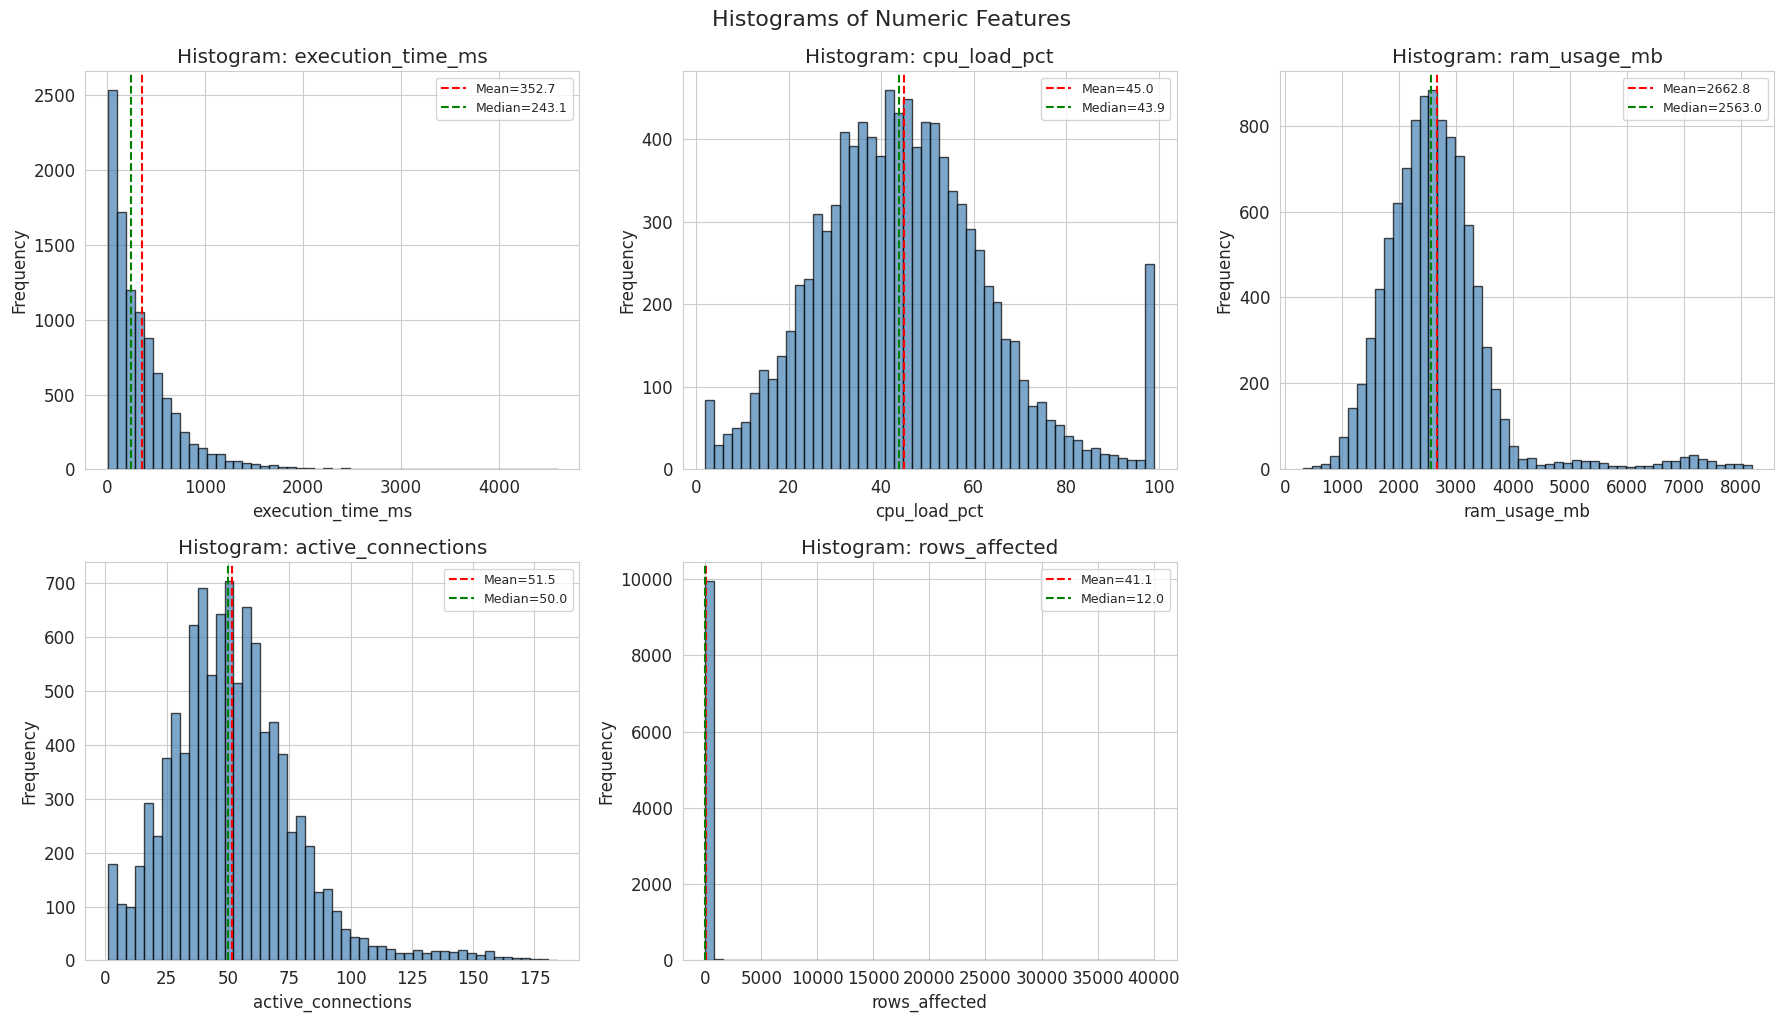

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    ax.hist(df[col], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    ax.axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean={df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='green', linestyle='--', label=f'Median={df[col].median():.1f}')
    ax.set_title(f'Histogram: {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=9)

axes[5].set_visible(False)
plt.tight_layout()
plt.suptitle('Histograms of Numeric Features', fontsize=16, y=1.02)
plt.show()

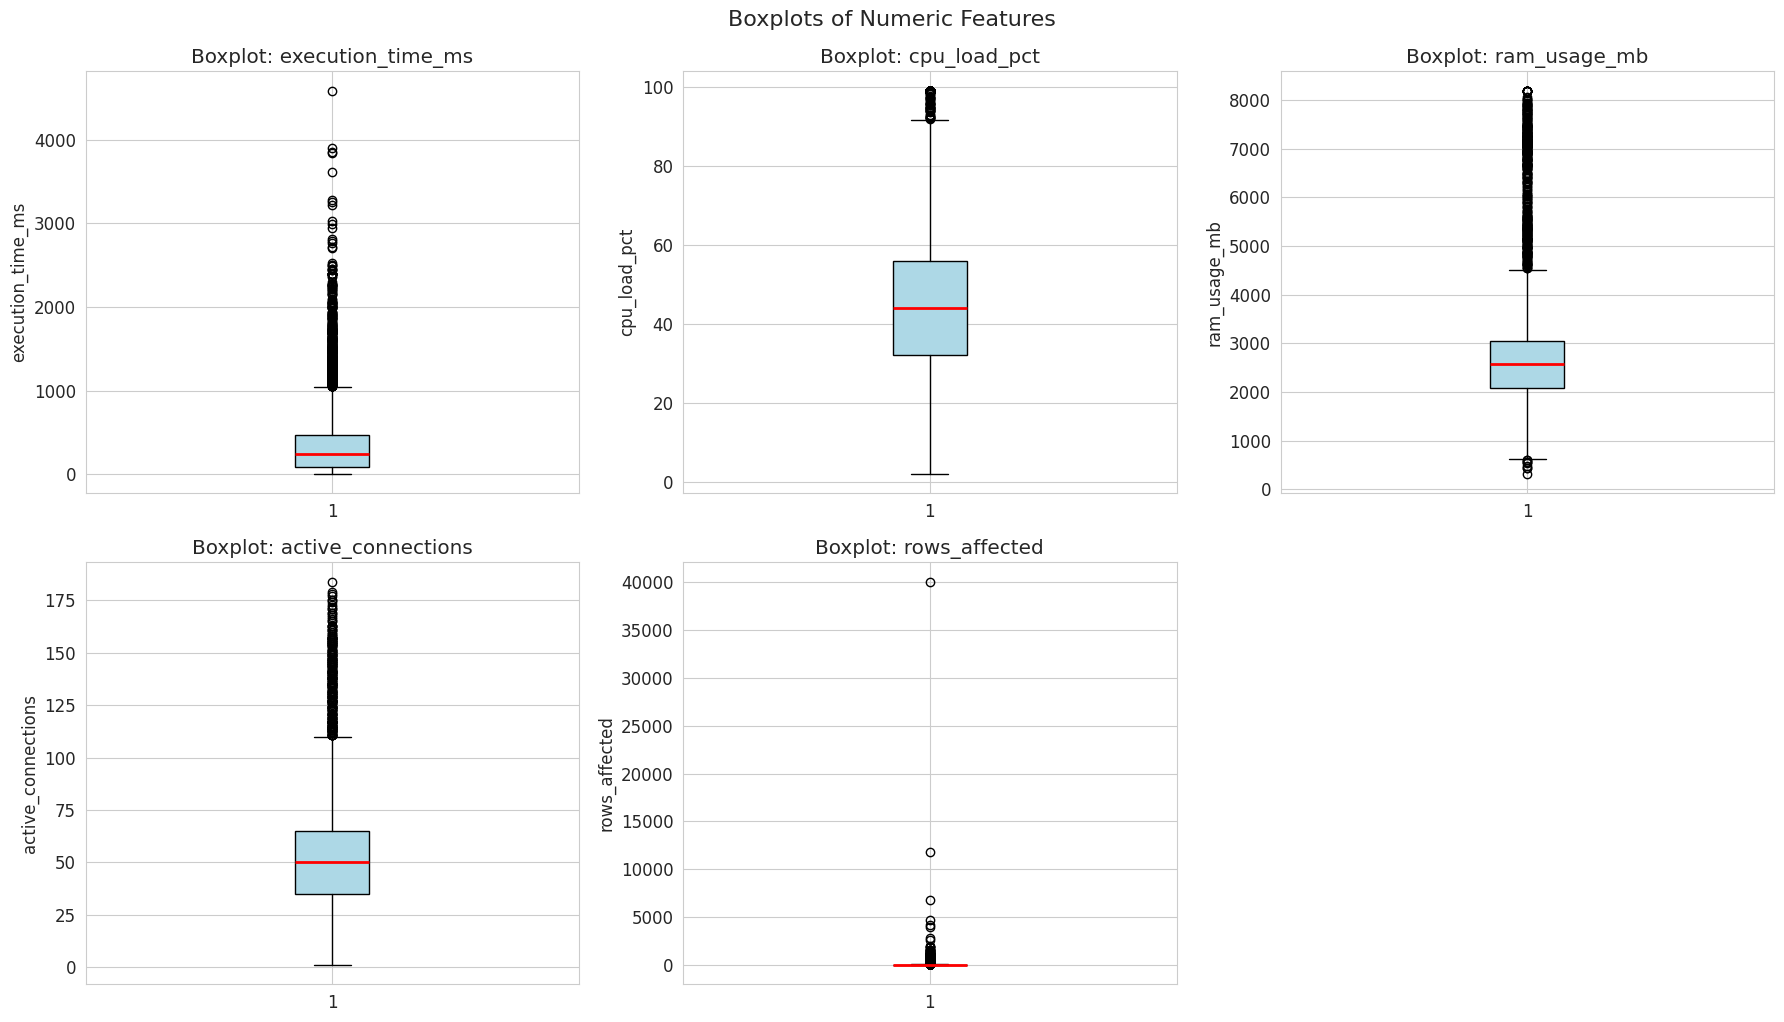

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    bp = ax.boxplot(df[col], vert=True, patch_artist=True,
                    boxprops=dict(facecolor='lightblue'),
                    medianprops=dict(color='red', linewidth=2))
    ax.set_title(f'Boxplot: {col}')
    ax.set_ylabel(col)

axes[5].set_visible(False)
plt.tight_layout()
plt.suptitle('Boxplots of Numeric Features', fontsize=16, y=1.02)
plt.show()

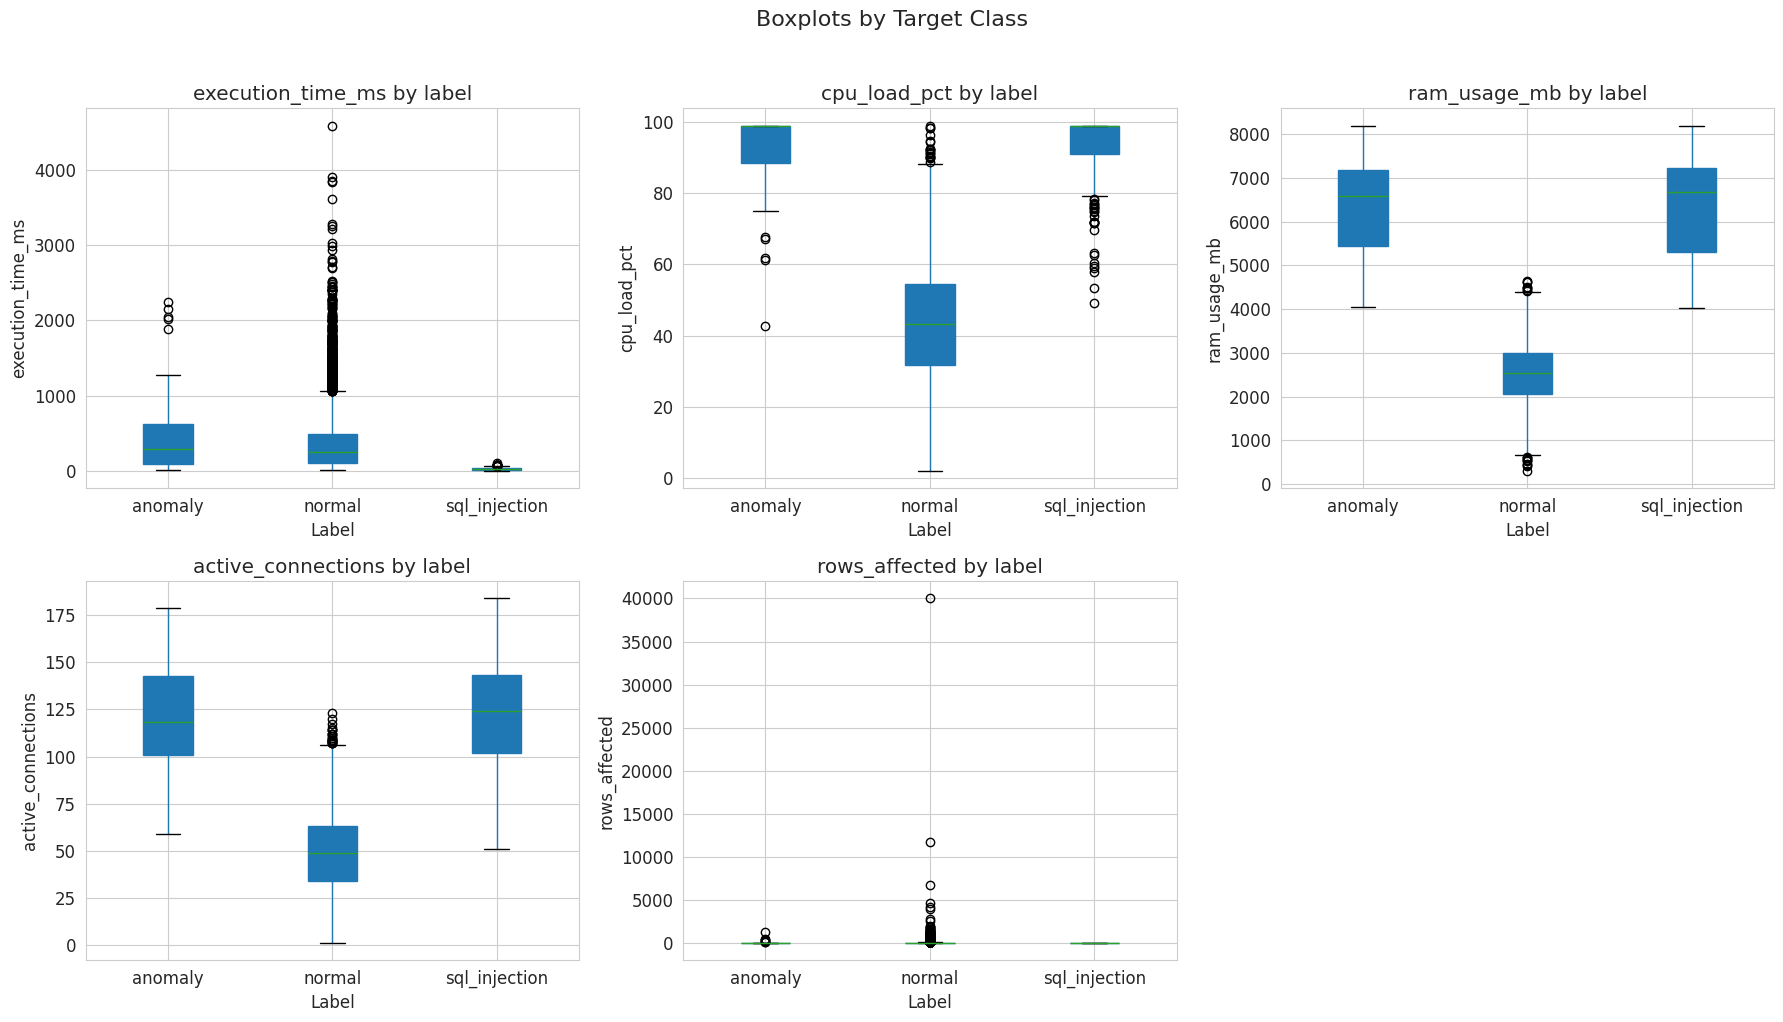

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    df.boxplot(column=col, by='label', ax=ax, patch_artist=True)
    ax.set_title(f'{col} by label')
    ax.set_xlabel('Label')
    ax.set_ylabel(col)

axes[5].set_visible(False)
plt.tight_layout()
plt.suptitle('Boxplots by Target Class', fontsize=16, y=1.02)
plt.show()

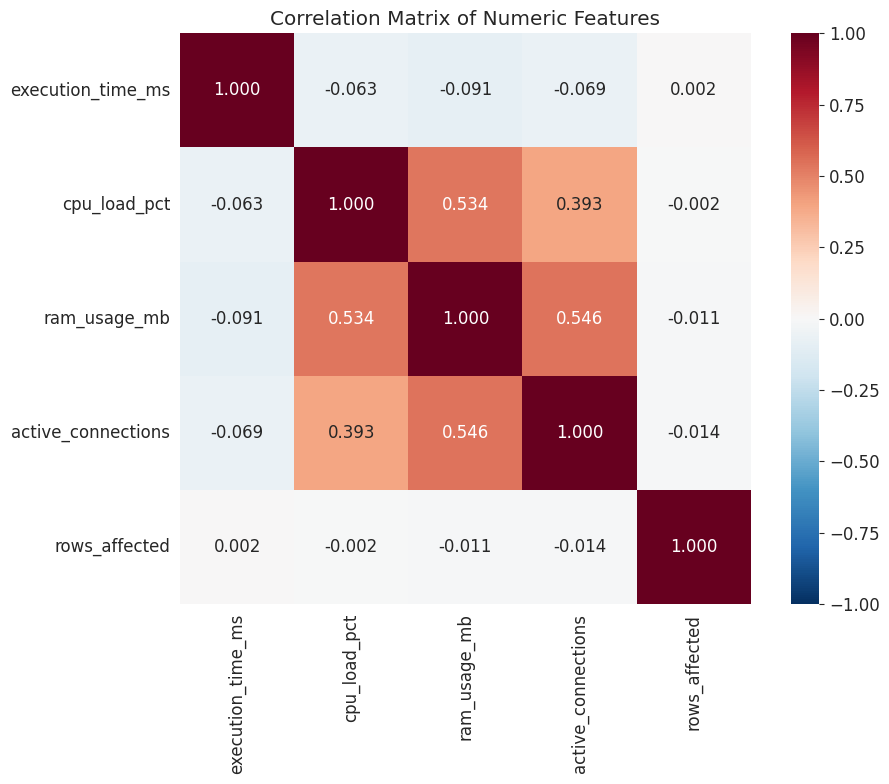

In [18]:
corr_matrix = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            square=True, ax=ax, vmin=-1, vmax=1)
ax.set_title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

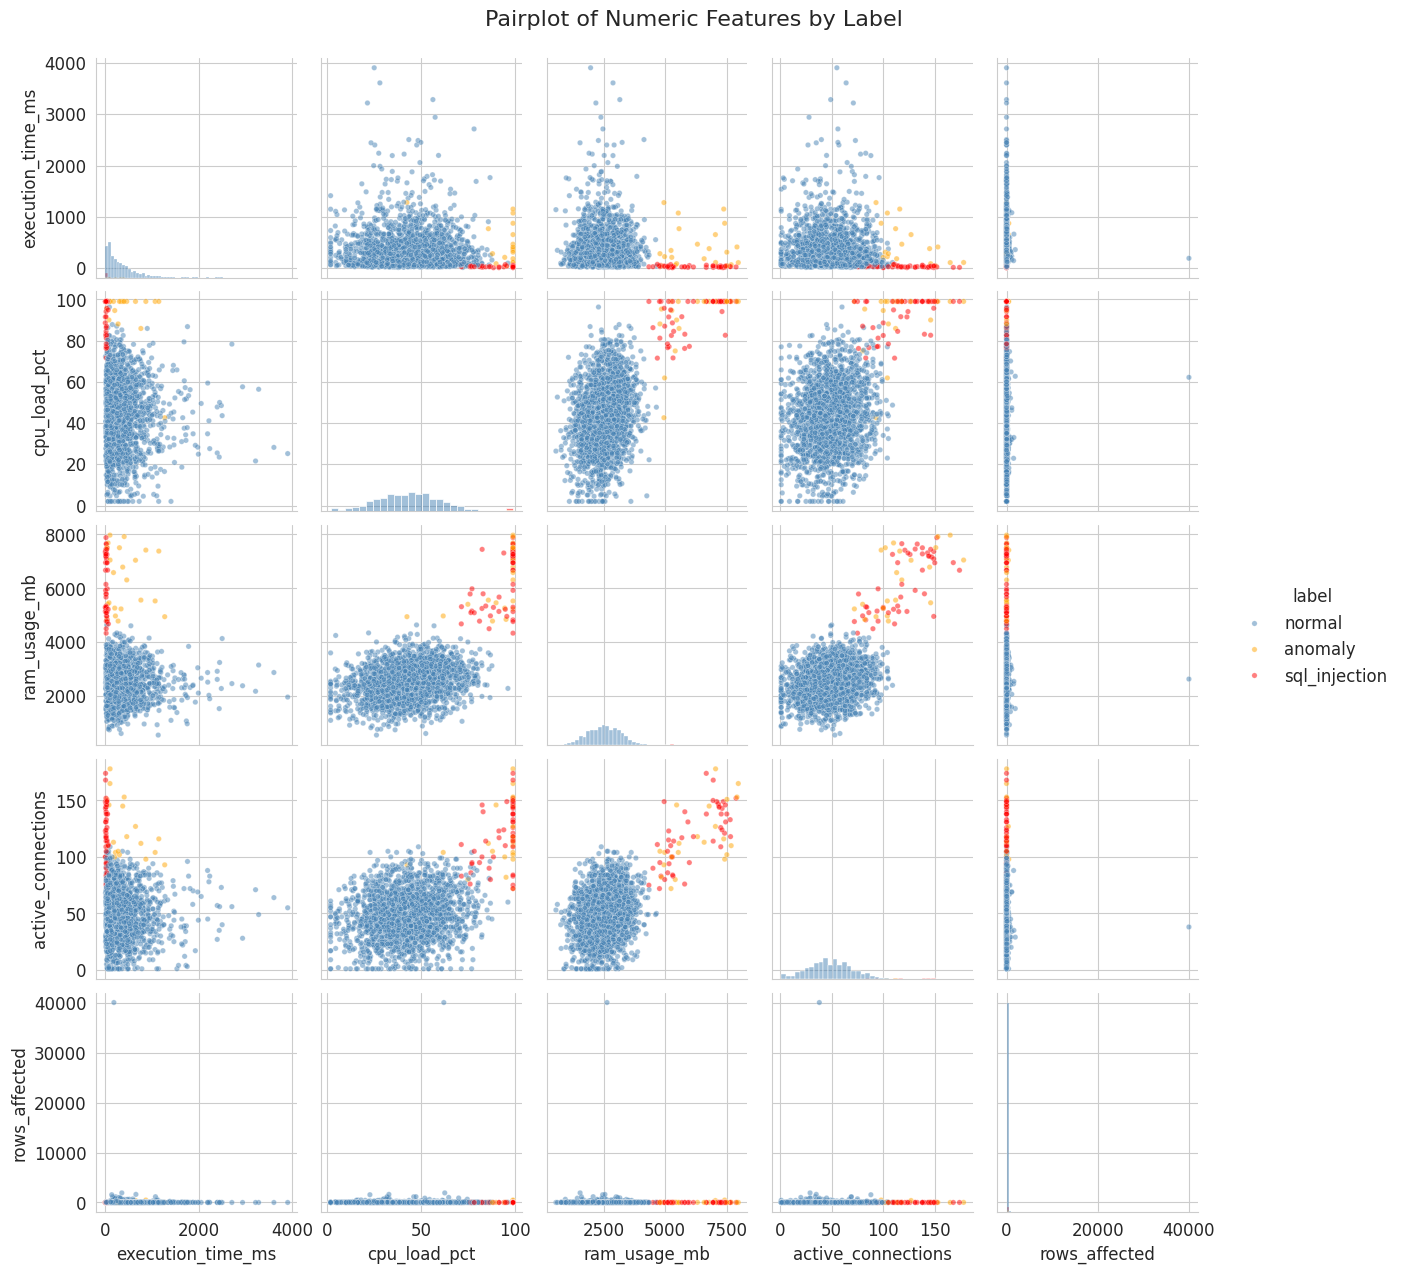

In [19]:
sample = df.sample(n=2000, random_state=42)
sns.pairplot(sample[num_cols + ['label']], hue='label', 
             palette={'normal': 'steelblue', 'sql_injection': 'red', 'anomaly': 'orange'},
             plot_kws={'alpha': 0.5, 's': 15}, diag_kind='hist')
plt.suptitle('Pairplot of Numeric Features by Label', y=1.02, fontsize=16)
plt.show()

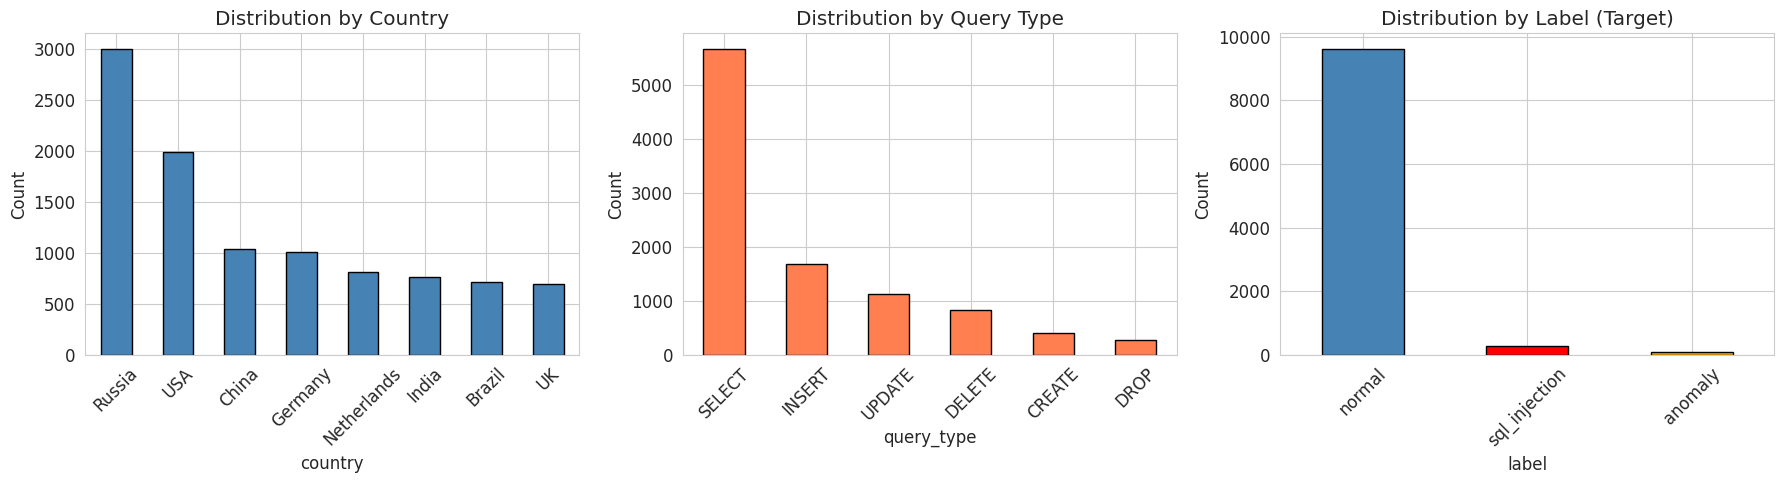

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df['country'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Distribution by Country')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

df['query_type'].value_counts().plot(kind='bar', ax=axes[1], color='coral', edgecolor='black')
axes[1].set_title('Distribution by Query Type')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

df['label'].value_counts().plot(kind='bar', ax=axes[2], 
                                 color=['steelblue', 'red', 'orange'], edgecolor='black')
axes[2].set_title('Distribution by Label (Target)')
axes[2].set_ylabel('Count')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

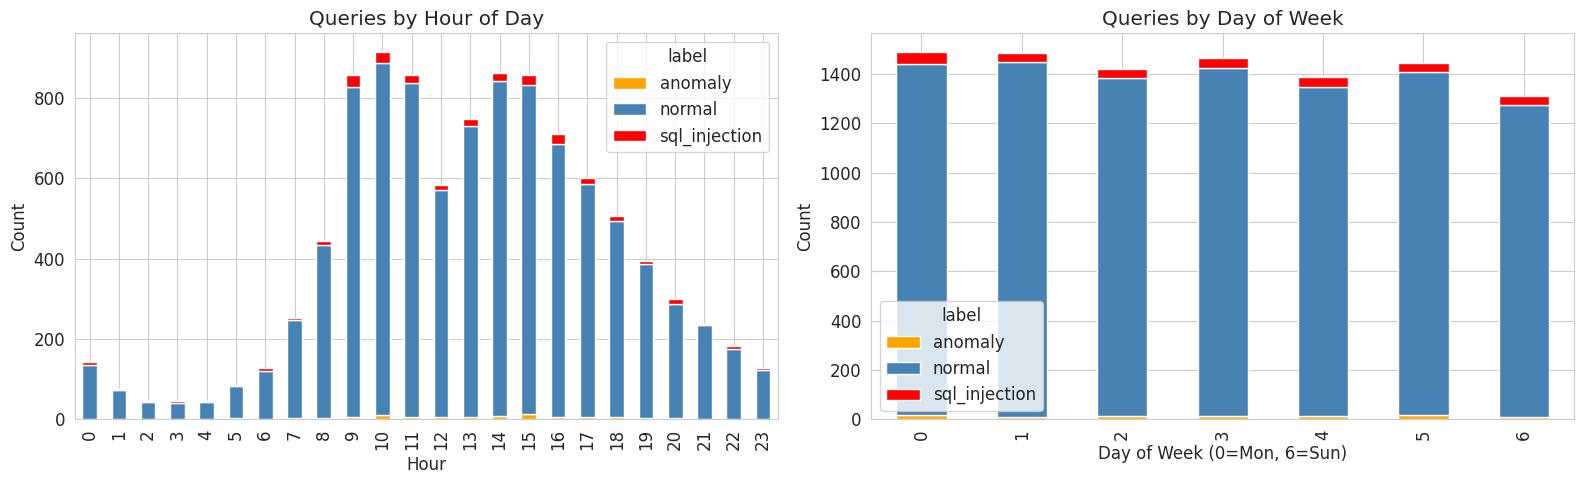

In [21]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df.groupby(['hour', 'label']).size().unstack(fill_value=0).plot(kind='bar', stacked=True, ax=axes[0],
    color={'normal': 'steelblue', 'sql_injection': 'red', 'anomaly': 'orange'})
axes[0].set_title('Queries by Hour of Day')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Count')

df.groupby(['day_of_week', 'label']).size().unstack(fill_value=0).plot(kind='bar', stacked=True, ax=axes[1],
    color={'normal': 'steelblue', 'sql_injection': 'red', 'anomaly': 'orange'})
axes[1].set_title('Queries by Day of Week')
axes[1].set_xlabel('Day of Week (0=Mon, 6=Sun)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

## 1.3. Предобработка данных

In [28]:
df_work = df.copy()

cols_to_drop = ['ip_address', 'sql_query', 'timezone', 'is_anomaly', 'timestamp']
df_work = df_work.drop(columns=cols_to_drop)

print(f'Признаки удалены: {cols_to_drop}')
print(f'Оставшиеся признаки ({df_work.shape[1]}): {list(df_work.columns)}')
print(f'Размерность: {df_work.shape}')

Признаки удалены: ['ip_address', 'sql_query', 'timezone', 'is_anomaly', 'timestamp']
Оставшиеся признаки (11): ['country', 'city', 'query_type', 'execution_time_ms', 'cpu_load_pct', 'ram_usage_mb', 'active_connections', 'rows_affected', 'label', 'hour', 'day_of_week']
Размерность: (10000, 11)


In [29]:
df_work = df_work.drop(columns=['city'])

y = df_work['label']
X = df_work.drop(columns=['label'])

X_encoded = pd.get_dummies(X, columns=['country', 'query_type'], drop_first=True)

X_encoded.head()

,execution_time_ms,cpu_load_pct,ram_usage_mb,active_connections,rows_affected,hour,day_of_week,country_China,country_Germany,country_India,country_Netherlands,country_Russia,country_UK,country_USA,query_type_DELETE,query_type_DROP,query_type_INSERT,query_type_SELECT,query_type_UPDATE
0,24.54,84.5,5345,114,0,0,0,False,True,False,False,False,False,False,False,False,False,True,False
1,550.83,23.6,1968,7,19,0,0,False,False,False,False,True,False,False,False,False,False,True,False
2,465.76,55.9,3011,45,24,2,0,False,False,False,False,False,False,False,False,False,False,True,False
3,111.08,32.6,2076,48,50,3,0,False,False,False,True,False,False,False,True,False,False,False,False
4,199.06,42.6,2175,19,5,4,0,False,False,False,False,True,False,False,False,False,False,True,False


In [31]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

for i, cls in enumerate(le.classes_):
    print(f'  {cls} = {i}')
print(f'\nРаспределение: {np.bincount(y_encoded)}')

  anomaly = 0
  normal = 1
  sql_injection = 2

Распределение: [ 100 9624  276]


## 1.4. Нормализация и стандартизация данных

In [32]:
num_features = ['execution_time_ms', 'cpu_load_pct', 'ram_usage_mb', 
                'active_connections', 'rows_affected', 'hour', 'day_of_week']

scaler = StandardScaler()
X_scaled = X_encoded.copy()
X_scaled[num_features] = scaler.fit_transform(X_encoded[num_features])

print(X_encoded[num_features].describe().loc[['mean', 'std']].round(2))
print(X_scaled[num_features].describe().loc[['mean', 'std']].round(4))

      execution_time_ms  cpu_load_pct  ram_usage_mb  active_connections  \
mean             352.66         44.97       2662.77               51.48   
std              371.68         18.80        995.82               25.56   

      rows_affected   hour  day_of_week  
mean          41.10  13.10         2.93  
std          442.66   4.59         1.99  
      execution_time_ms  cpu_load_pct  ram_usage_mb  active_connections  \
mean             0.0000        0.0000        0.0000              0.0000   
std              1.0001        1.0001        1.0001              1.0001   

      rows_affected    hour  day_of_week  
mean        -0.0000  0.0000      -0.0000  
std          1.0001  1.0001       1.0001  


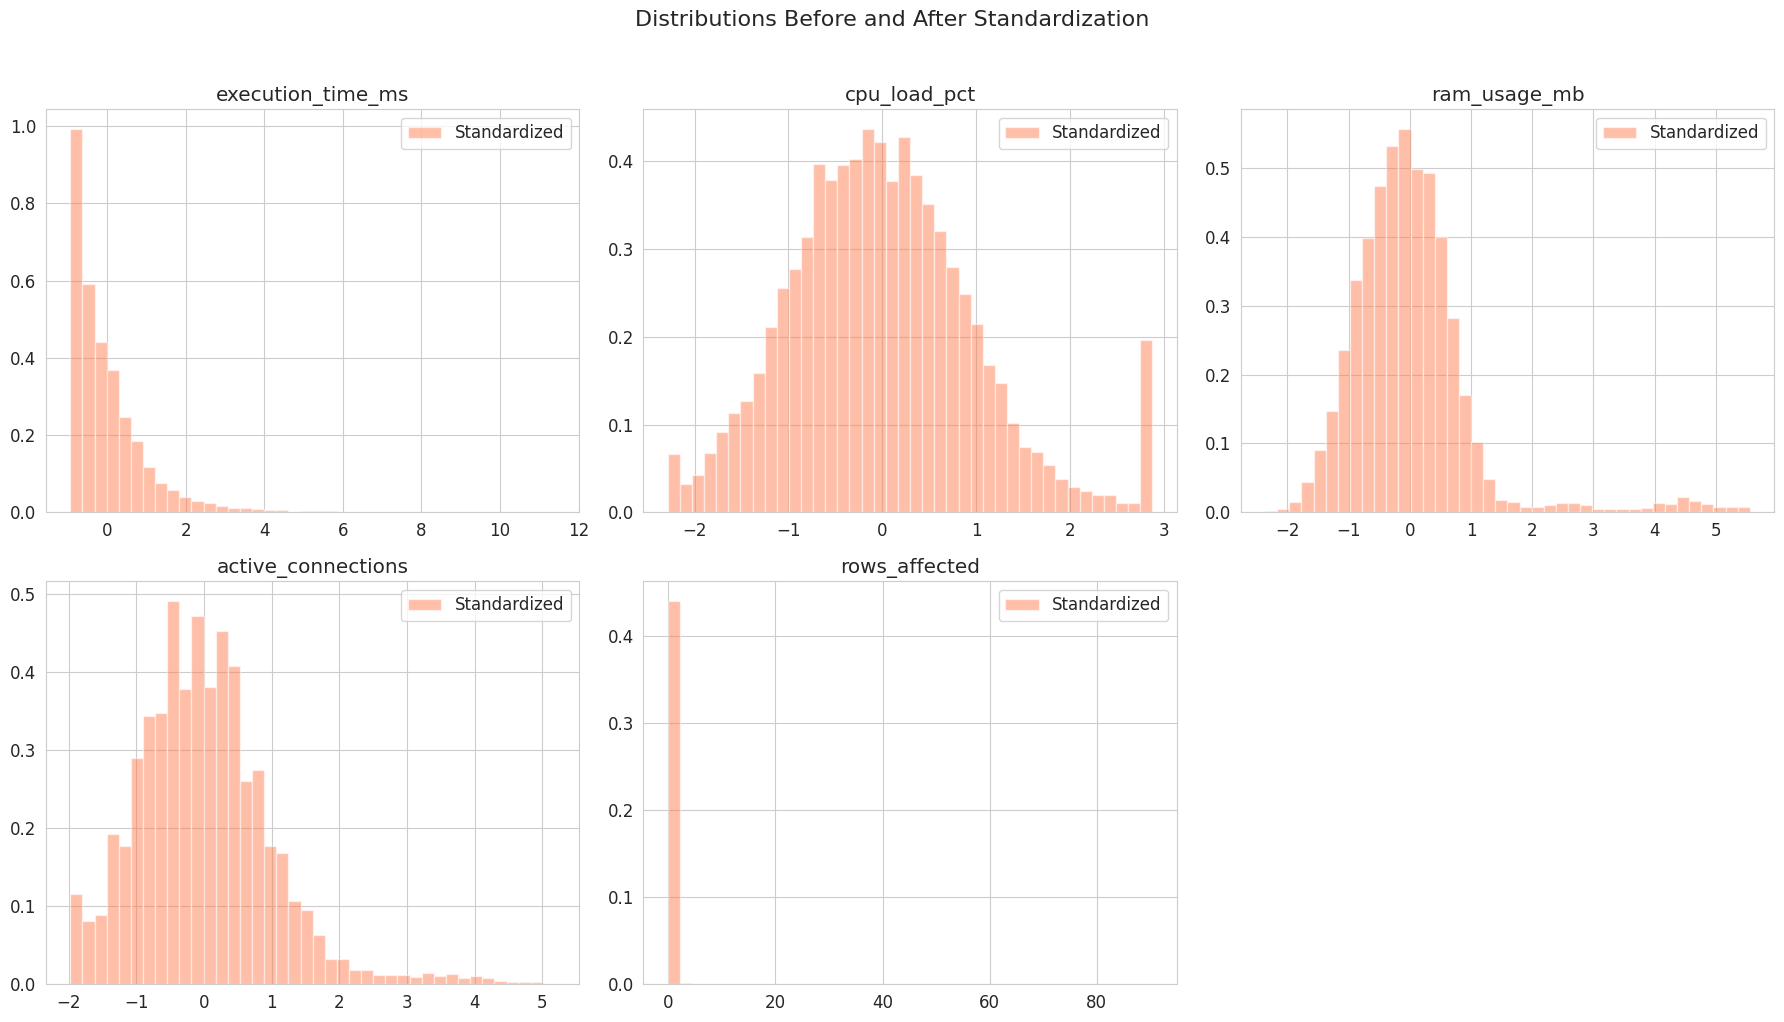

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_features[:5]):
    ax = axes[i]
    ax.hist(X_scaled[col], bins=40, alpha=0.5, label='Standardized', color='coral', density=True)
    ax.set_title(f'{col}')
    ax.legend()

axes[5].set_visible(False)
plt.suptitle('Distributions After Standardization', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 1.5. Разделение данных на обучающую и тестовую выборки

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_encoded
)

print(f'Обучающая выборка: X_train {X_train.shape}, y_train {y_train.shape}')
print(f'Тестовая выборка:  X_test  {X_test.shape},  y_test  {y_test.shape}')

print(f'\n=== Проверка стратификации ===')
print(f'Распределение в полной выборке:   {np.bincount(y_encoded) / len(y_encoded)}')
print(f'Распределение в train:            {np.bincount(y_train) / len(y_train)}')
print(f'Распределение в test:             {np.bincount(y_test) / len(y_test)}')

Обучающая выборка: X_train (8000, 19), y_train (8000,)
Тестовая выборка:  X_test  (2000, 19),  y_test  (2000,)

=== Проверка стратификации ===
Распределение в полной выборке:   [0.01   0.9624 0.0276]
Распределение в train:            [0.01     0.962375 0.027625]
Распределение в test:             [0.01   0.9625 0.0275]


## 1.6. Итоги


**Набор данных**: 10 000 записей логов PostgreSQL-сервера, 14 исходных признаков. Задача — **многоклассовая классификация** (normal / sql_injection / anomaly).

**Качество данных**: пропуски отсутствуют, что упростило предобработку. Выявлен значительный **дисбаланс классов** (96.2% / 2.8% / 1.0%), который необходимо учитывать на этапе моделирования (SMOTE, class_weight, метрики: F1, ROC-AUC).

**Визуализация** выявила:
   - Правостороннюю асимметрию в execution_time_ms и rows_affected
   - Выбросы, коррелирующие с аномальными запросами
   - Слабые корреляции между признаками (мультиколлинеарность не является проблемой)
   - Различия в профилях нагрузки для разных классов

**Предобработка** включала:
   - Удаление нерелевантных/избыточных признаков (5 из 14)
   - Feature engineering (извлечение hour, day_of_week)
   - One-Hot кодирование категориальных признаков
   - Стандартизацию числовых признаков

**Итоговая размерность**: 18 признаков (7 числовых + 12 бинарных - 1 drop_first для каждой категории).

| Метод | Применимость | Комментарий |
|-------|-------------|-------------|
| Гистограммы | **Обязательно** | Оценка формы распределения, выбор метода заполнения пропусков |
| Boxplot | **Обязательно** | Выявление выбросов, сравнение классов |
| Корреляционная матрица | **Обязательно** | Обнаружение мультиколлинеарности |
| Диаграммы рассеяния | Желательно | Визуализация разделимости классов |
| One-Hot кодирование | **Обязательно** | Для номинальных признаков при использовании метрических моделей |
| Стандартизация | **Обязательно** | Для kNN, SVM, логрег; нежелательна для деревьев |
| Min-Max нормализация | Нежелательно | Чувствительна к выбросам (в данных есть выбросы) |
| Удаление выбросов | Нежелательно | Выбросы связаны с целевым классом, их удаление потеряет информацию |
| Стратифицированное разбиение | **Обязательно** | При дисбалансе классов |

**Готовность данных**

Набор данных подготовлен к использованию в последующих практических работах. Для улучшения качества классификации рекомендуется рассмотреть методы борьбы с дисбалансом на этапе моделирования.